In [98]:
import saikit_learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [99]:
from saikit_learn.regression import OLS, Ridge, Lasso, PolReg
from saikit_learn.decision_tree import DecisionTreeRegressor
from saikit_learn.neural_network import MLPRegressor
from saikit_learn.preprocessing import StandardScaler, Pipeline
from saikit_learn.regression_metrics import MSE, RMSE, MAE, RSS, R2, R2_ajusted

In [100]:
df_treino = pd.read_csv("../../../data/processed/treino_regressao.csv")
df_teste = pd.read_csv("../../../data/processed/teste_regressao.csv")

print("Treinamento:", df_treino.shape)
print("Teste:", df_teste.shape)

Treinamento: (14838, 82)
Teste: (6359, 82)


In [101]:
#Separando para ter os conjuntos de treino, validação e teste
df_ajuste = df_treino.sample(frac=0.8, random_state=42)
df_valid = df_treino.drop(df_ajuste.index)

print("Ajuste:", df_ajuste.shape)
print("Validação:", df_valid.shape)

Ajuste: (11870, 82)
Validação: (2968, 82)


In [102]:
# Correlação Pearson entre as variáveis com a variável alvo - DS 
correlacoes = df_ajuste.corr()["critical_temp"].drop("critical_temp")
correlacoes.abs().sort_values(ascending=False).head(10)

wtd_std_ThermalConductivity    0.715276
range_ThermalConductivity      0.680639
range_atomic_radius            0.652881
std_ThermalConductivity        0.645879
wtd_mean_Valence               0.631212
wtd_entropy_atomic_mass        0.620912
wtd_gmean_Valence              0.614361
mean_Valence                   0.601164
wtd_std_atomic_radius          0.600847
range_fie                      0.600627
Name: critical_temp, dtype: float64

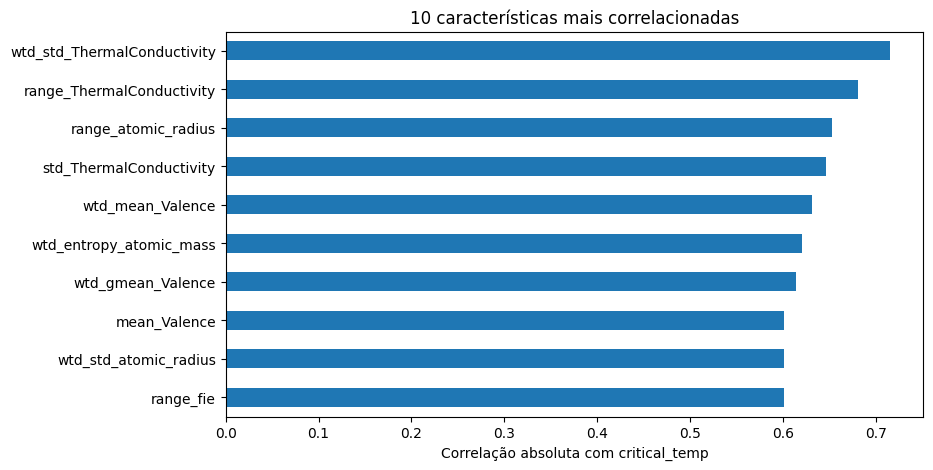

In [103]:
correlacoes.abs().sort_values(ascending=False).head(10).sort_values().plot(kind="barh",figsize=(9, 5))

plt.xlabel("Correlação absoluta com critical_temp")
plt.title("10 características mais correlacionadas")
plt.show()

In [104]:
#Conversão numpy - formato da biblioteca
X_train = df_ajuste.drop(columns=["critical_temp"]).to_numpy()
y_train = df_ajuste["critical_temp"].to_numpy()

X_valid = df_valid.drop(columns=["critical_temp"]).to_numpy()
y_valid = df_valid["critical_temp"].to_numpy()

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_valid:", X_valid.shape)
print("y_valid:", y_valid.shape)

X_train: (11870, 81)
y_train: (11870,)
X_valid: (2968, 81)
y_valid: (2968,)


In [105]:
# Precisamos guardar o scaler para aplicar na validação a mesma padronização aprendida no treino para evitando vazamento de dados
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

In [106]:
#BASELINE para comparação dos modelos - média direta das temperaturas críticas do conjunto de treino

media_treino = y_train.mean()
y_pred_baseline = np.full(len(y_valid), media_treino)
print("MSE:", MSE(y_valid, y_pred_baseline))
print("RMSE:", RMSE(y_valid, y_pred_baseline))
print("MAE:", MAE(y_valid, y_pred_baseline))
print("R²:", R2(y_valid, y_pred_baseline))

MSE: 1176.694120105377
RMSE: 34.302975382689134
MAE: 29.470435675333864
R²: -3.551079109564981e-05


### OLS - Primeiro Modelo

In [107]:
modelo_ols = OLS()
modelo_ols.fit(X_train_scaled, y_train)
y_pred_ols = modelo_ols.predict(X_valid_scaled)
print("MSE:", MSE(y_valid, y_pred_ols))
print("RMSE:", RMSE(y_valid, y_pred_ols))
print("MAE:", MAE(y_valid, y_pred_ols))
print("R²:", R2(y_valid, y_pred_ols))

MSE: 318.78210833961464
RMSE: 17.854470262083236
MAE: 13.40866192411901
R²: 0.7290770616615982


In [108]:
#Tabela de compraração dos resultados dos modelos para compararmos
resultados = pd.DataFrame({
    "Modelo": ["Baseline", "OLS"],
    "MSE": [MSE(y_valid, y_pred_baseline),MSE(y_valid, y_pred_ols)],
    "RMSE": [RMSE(y_valid, y_pred_baseline),RMSE(y_valid, y_pred_ols)],
    "MAE": [MAE(y_valid, y_pred_baseline),MAE(y_valid, y_pred_ols)],
    "R2": [R2(y_valid, y_pred_baseline),R2(y_valid, y_pred_ols)]})

resultados

,Modelo,MSE,RMSE,MAE,R2
0,Baseline,1176.694120,34.302975,29.470436,-0.000036
1,OLS,318.782108,17.854470,13.408662,0.729077


In [109]:
# De cara verificamos um desempenho bem melhor do OLS, em comparação com o baseline. Ainda sim, pelo R2 vemos que temos espaço de melhoria, 
# o proximo passo é tentar melhorá-lo com regularização, para isso vamos testar o Ridge e o Lasso.

### Ridge

In [110]:
#testar diferentes penalizações ridge 
lambdas_ridge = [0.1, 1, 10, 100, 1000]
resultados_ridge = []

for lmbd in lambdas_ridge:
    modelo = Ridge(lmbd=lmbd)
    modelo.fit(X_train_scaled, y_train)
    previsoes = modelo.predict(X_valid_scaled)
    resultados_ridge.append([lmbd,RMSE(y_valid, previsoes),MAE(y_valid, previsoes),R2(y_valid, previsoes)])

tabela_ridge = pd.DataFrame(resultados_ridge,columns=["Lambda", "RMSE", "MAE", "R2"])

tabela_ridge.sort_values("RMSE")

,Lambda,RMSE,MAE,R2
0,0.1,17.852273,13.405925,0.729144
1,1.0,17.859032,13.416301,0.728939
2,10.0,17.932614,13.502233,0.726700
3,100.0,18.314938,13.886649,0.714923
4,1000.0,19.200200,14.788959,0.686698


In [111]:
# escolher melhor lambda para o ridge

melhor_lambda_ridge = tabela_ridge.loc[tabela_ridge["RMSE"].idxmin(), "Lambda"]

modelo_ridge = Ridge(lmbd=melhor_lambda_ridge)
modelo_ridge.fit(X_train_scaled, y_train)
y_pred_ridge = modelo_ridge.predict(X_valid_scaled)
print("Melhor lambda:", melhor_lambda_ridge)
print("RMSE:", RMSE(y_valid, y_pred_ridge))
print("R2:", R2(y_valid, y_pred_ridge))

Melhor lambda: 0.1
RMSE: 17.852273117451446
R2: 0.729143736308916


### Lasso


In [112]:
# mesmo padrão do Riege
lambdas_lasso = [0.1, 1, 5]
resultados_lasso = []

for lmbd in lambdas_lasso:
    modelo = Lasso(lmbd=lmbd)
    modelo.fit(X_train_scaled, y_train)
    previsoes = modelo.predict(X_valid_scaled)

    resultados_lasso.append([lmbd,RMSE(y_valid, previsoes),MAE(y_valid, previsoes),R2(y_valid, previsoes)])

tabela_lasso = pd.DataFrame(resultados_lasso,columns=["Lambda", "RMSE", "MAE", "R2"])

tabela_lasso.sort_values("RMSE")

,Lambda,RMSE,MAE,R2
0,0.1,18.674840,14.210691,0.703609
1,1.0,20.430796,15.891247,0.645250
2,5.0,22.903725,17.853007,0.554175


In [113]:
# escolher melhjor lambda para o lasso
melhor_lambda_lasso = tabela_lasso.loc[tabela_lasso["RMSE"].idxmin(), "Lambda"]

modelo_lasso = Lasso(lmbd=melhor_lambda_lasso)
modelo_lasso.fit(X_train_scaled, y_train)
y_pred_lasso = modelo_lasso.predict(X_valid_scaled)
print("Melhor lambda:", melhor_lambda_lasso)
print("RMSE:", RMSE(y_valid, y_pred_lasso))
print("R2:", R2(y_valid, y_pred_lasso))

Melhor lambda: 0.1
RMSE: 18.674840475886707
R2: 0.7036085714908255


In [114]:
# Atualizando a tabela de comparaçãocom os resultados do Ridge e Lasso

resultados.loc[len(resultados)] = [
    "Ridge",MSE(y_valid, y_pred_ridge),RMSE(y_valid, y_pred_ridge),MAE(y_valid, y_pred_ridge),R2(y_valid, y_pred_ridge)]
resultados.loc[len(resultados)] = [ "Lasso",MSE(y_valid, y_pred_lasso),RMSE(y_valid, y_pred_lasso),MAE(y_valid, y_pred_lasso),
                                   R2(y_valid, y_pred_lasso)]
resultados.sort_values("RMSE")

,Modelo,MSE,RMSE,MAE,R2
2,Ridge,318.703655,17.852273,13.405925,0.729144
1,OLS,318.782108,17.854470,13.408662,0.729077
3,Lasso,348.749667,18.674840,14.210691,0.703609
0,Baseline,1176.694120,34.302975,29.470436,-0.000036


O riedge apresentou o melhor desempenho geral, com RMSE de 17 e R2 de 0,71. Apesar de ter sido quase o mesmo que o OLS. Por outro lado, o Lasso apresentou piora. Por fim, os tres modelos, até o momento, já superam o Baseline. 

### Arvore de Decisão

In [115]:
profundidades = [3, 5, 8, 12, 14, 16]
resultados_arvore = []

for profundidade in profundidades:
    modelo = DecisionTreeRegressor(max_depth=profundidade)
    modelo.fit(X_train, y_train)
    pred_train = modelo.predict(X_train)
    pred_valid = modelo.predict(X_valid)
    resultados_arvore.append([profundidade,RMSE(y_train, pred_train),RMSE(y_valid, pred_valid)])

tabela_arvore = pd.DataFrame(resultados_arvore,columns=["Profundidade", "RMSE_treino", "RMSE_valid"])
tabela_arvore.sort_values("RMSE_valid")

# Testando 6 profundidades diferentes para a árvore de decisão. Calculo o RMSE no treino e na validação e comparamos os erros
# verificando algum overfitting. 

,Profundidade,RMSE_treino,RMSE_valid
4,14,6.166099,12.620247
5,16,5.070229,12.676802
3,12,7.748281,12.867761
2,8,12.086629,14.002700
1,5,15.998060,16.688236
0,3,18.897375,18.887893


In [116]:
melhor_profundidade = int(tabela_arvore.loc[tabela_arvore["RMSE_valid"].idxmin(), "Profundidade"])
modelo_arvore = DecisionTreeRegressor(max_depth=melhor_profundidade)
modelo_arvore.fit(X_train, y_train)
y_pred_arvore = modelo_arvore.predict(X_valid)
print("Melhor profundidade:", melhor_profundidade)
print("MSE:", MSE(y_valid, y_pred_arvore))
print("RMSE:", RMSE(y_valid, y_pred_arvore))
print("MAE:", MAE(y_valid, y_pred_arvore))
print("R2:", R2(y_valid, y_pred_arvore))

Melhor profundidade: 14
MSE: 159.27062527032862
RMSE: 12.620246640629835
MAE: 6.937092438912534
R2: 0.8646408795839258


Vamos escolher a melhor profundidade baseado pelo erro de validação. 

Uma arvore muito profunda pode apresentar um RMSE pequeni no treino, mas alto na validação, isso significaria um ajuste excessivo aos dados conhecidos. 

In [117]:
# Acrescentando a tabela de comparação 
resultados.loc[len(resultados)] = ["Árvore de decisão",
    MSE(y_valid, y_pred_arvore),
    RMSE(y_valid, y_pred_arvore),
    MAE(y_valid, y_pred_arvore),
    R2(y_valid, y_pred_arvore)]

resultados.sort_values("RMSE")

,Modelo,MSE,RMSE,MAE,R2
4,Árvore de decisão,159.270625,12.620247,6.937092,0.864641
2,Ridge,318.703655,17.852273,13.405925,0.729144
1,OLS,318.782108,17.854470,13.408662,0.729077
3,Lasso,348.749667,18.674840,14.210691,0.703609
0,Baseline,1176.694120,34.302975,29.470436,-0.000036


A arvore de decisão com profundidade 14 apresentou o desempenho até o momento, com RMSE de 12,6 K e R2 de 0,865. O desempenho superior do modelo de arvores lineares, em relação aos modelos lineares, levanta uma hipotese de que existem relações não lineares relevantes entre as características dos materiais e a temperatura crítica. Por outro lado, a diferença entre os erros de treino e validação sugere que pode ter um sobreajuste, com destaque para as arvores mais profundas. 

### Redes Neurais

In [118]:
modelo_mlp = MLPRegressor(
    hidden_layers=(16,), #16 neurônios na camada oculta
    learning_rate=0.001, # taxa de aprendizado
    n_epochs=300, #qt de epocas de treinamento - começar baixo para ser rapido
    random_state=42) #garantia de reprodutibilidade

modelo_mlp.fit(X_train_scaled, y_train) #treino
y_pred_mlp = modelo_mlp.predict(X_valid_scaled)

In [119]:
print("MSE:", MSE(y_valid, y_pred_mlp))
print("RMSE:", RMSE(y_valid, y_pred_mlp))
print("MAE:", MAE(y_valid, y_pred_mlp))
print("R2:", R2(y_valid, y_pred_mlp))
print("RMSE treino:", RMSE(y_train, modelo_mlp.predict(X_train_scaled)))
#avaliando no conjunto de validação

MSE: 307.46951220104046
RMSE: 17.534808587522146
MAE: 12.226555253740424
R2: 0.7386912831185724
RMSE treino: 17.28685713678961


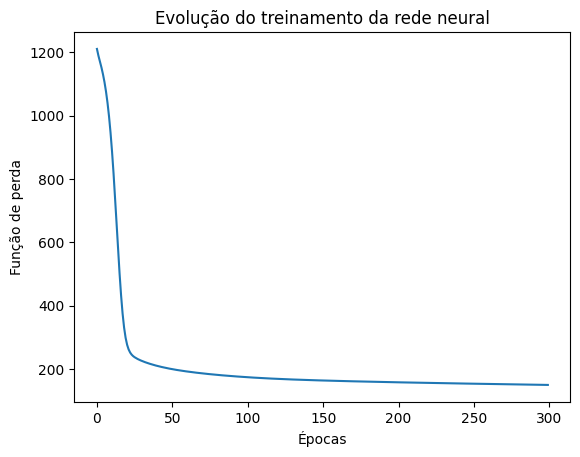

In [120]:
plt.plot(modelo_mlp._loss_history)
plt.xlabel("Épocas")
plt.ylabel("Função de perda")
plt.title("Evolução do treinamento da rede neural")
plt.show()

In [121]:
resultados.loc[len(resultados)] = [
    "Rede Neural (MLP)",
    MSE(y_valid, y_pred_mlp),
    RMSE(y_valid, y_pred_mlp),
    MAE(y_valid, y_pred_mlp),
    R2(y_valid, y_pred_mlp)]
resultados.sort_values("RMSE")

,Modelo,MSE,RMSE,MAE,R2
4,Árvore de decisão,159.270625,12.620247,6.937092,0.864641
5,Rede Neural (MLP),307.469512,17.534809,12.226555,0.738691
2,Ridge,318.703655,17.852273,13.405925,0.729144
1,OLS,318.782108,17.854470,13.408662,0.729077
3,Lasso,348.749667,18.674840,14.210691,0.703609
0,Baseline,1176.694120,34.302975,29.470436,-0.000036


O RMSE da rede neural ficou próximo tanto no ajuste como na validação. 

In [122]:
configuracoes = [(16, 300), (16, 900), (32, 300), (32, 900)]
resultados_mlp = []

for neuronios, epocas in configuracoes:
    mlp = MLPRegressor(
        hidden_layers=(neuronios,),
        learning_rate=0.001,
        n_epochs=epocas,
        random_state=42,
    )
    mlp.fit(X_train_scaled, y_train)

    resultados_mlp.append({
        "Neurônios": neuronios,
        "Épocas": epocas,
        "RMSE treino": RMSE(y_train, mlp.predict(X_train_scaled)),
        "RMSE validação": RMSE(y_valid, mlp.predict(X_valid_scaled)),
    })

tabela_mlp = pd.DataFrame(resultados_mlp).sort_values("RMSE validação")
tabela_mlp

,Neurônios,Épocas,RMSE treino,RMSE validação
3,32,900,15.937029,16.426950
1,16,900,15.994366,16.485169
2,32,300,17.131012,17.432351
0,16,300,17.286857,17.534809


Aumentar o treunamento de 300 para 900 épocas reduziu o RMSE de validação, tanto com 16 quanto com 32 neuronios. Apesar disso, o aumento de 16 para 32 neuronios não trouxeram melhoras significativas. Entre os que testamos, a rede com 32 neuronios e 900 épocas obteve o menor RMSE de validação. 

In [ ]:
melhor_mlp = tabela_mlp.iloc[0]
rmse_mlp_valid = melhor_mlp["RMSE validação"]
rmse_arvore_valid = RMSE(y_valid, y_pred_arvore)
usar_mlp = rmse_mlp_valid < rmse_arvore_valid
print(f"Melhor MLP: {rmse_mlp_valid:.2f} K")
print(f"Árvore: {rmse_arvore_valid:.2f} K")
print("Modelo escolhido:", "MLP" if usar_mlp else "Árvore de decisão")

Melhor MLP: 16.43 K
Árvore: 12.62 K
Modelo escolhido: Árvore de decisão


A arvore de decisão com profundidade de 14 obteve RMSE de 12,62K na validação, contra 16,43K da melhor rede neural. Como a arvore apresentou o menor RMSE dentre os modelos que testamos, escolhemos ela e ravaliamos ela com validação e treino, mantendo teste reservado.

In [125]:
preditores = df_treino.columns.drop("critical_temp")
X_final = df_treino[preditores].to_numpy()
y_final = df_treino["critical_temp"].to_numpy()
X_teste = df_teste[preditores].to_numpy()
y_teste = df_teste["critical_temp"].to_numpy()

if usar_mlp:
    scaler_final = StandardScaler()
    X_final = scaler_final.fit_transform(X_final)
    X_teste = scaler_final.transform(X_teste)

    modelo_final = MLPRegressor(
        hidden_layers=(int(melhor_mlp["Neurônios"]),),
        learning_rate=0.001,
        n_epochs=int(melhor_mlp["Épocas"]),
        random_state=42,
    )
else:
    modelo_final = DecisionTreeRegressor(max_depth=melhor_profundidade)

modelo_final.fit(X_final, y_final)
y_pred_teste = modelo_final.predict(X_teste)

print(f"RMSE no teste: {RMSE(y_teste, y_pred_teste):.2f} K")
print(f"MAE no teste: {MAE(y_teste, y_pred_teste):.2f} K")
print(f"R2 no teste: {R2(y_teste, y_pred_teste):.3f}")

RMSE no teste: 13.11 K
MAE no teste: 7.00 K
R2 no teste: 0.857


No conjunto de teste, a arvore de decisão teve RMSE de 13,11K , MAE de 7K e R2 de 0,857. Em média, encontramos desempenho semelhante tanto no teste quanto na partição final (validação e treino)